## Imports

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from PIL import Image

## Data Preparation

In [56]:
wti_df = pd.read_csv('../data/raw/wti-daily.csv')
brent_df = pd.read_csv('../data/raw/brent-daily.csv')

wti_df['Date'] = pd.to_datetime(wti_df['Date'])
brent_df['Date'] = pd.to_datetime(brent_df['Date'])

wti_df = wti_df.set_index("Date")
brent_df = brent_df.set_index("Date")


sales_df = pd.read_excel('../data/raw/sales.xlsx')

img = Image.open('../data/raw/2.jpg')

print(wti_df.head())
print(wti_df.columns)
print('')
print(brent_df.head())
print('')
print(sales_df.head())

            Price
Date             
1986-01-02  25.56
1986-01-03  26.00
1986-01-06  26.53
1986-01-07  25.85
1986-01-08  25.87
Index(['Price'], dtype='str')

            Price
Date             
1987-05-20  18.63
1987-05-21  18.45
1987-05-22  18.55
1987-05-25  18.60
1987-05-26  18.63

    Invoice ID Branch       City Customer type  Gender  Product Code  \
0  123-19-1176      A     Yangon        Member    Male             1   
1  699-14-3026      C  Naypyitaw        Normal    Male             1   
2  355-53-5943      A     Yangon        Member  Female             1   
3  315-22-5665      C  Naypyitaw        Normal  Female             1   
4  692-92-5582      B   Mandalay        Member  Female             1   

   Unit price  Quantity   Tax 5%     Total       Date      Payment    COGS  \
0       58.22         8  23.2880  489.0480 2019-01-27      Ewallet  465.76   
1       85.39         7  29.8865  627.6165 2019-03-25      Ewallet  597.73   
2       68.84         6  20.6520  433.6920 2019-0

## Oil Prices Analysis

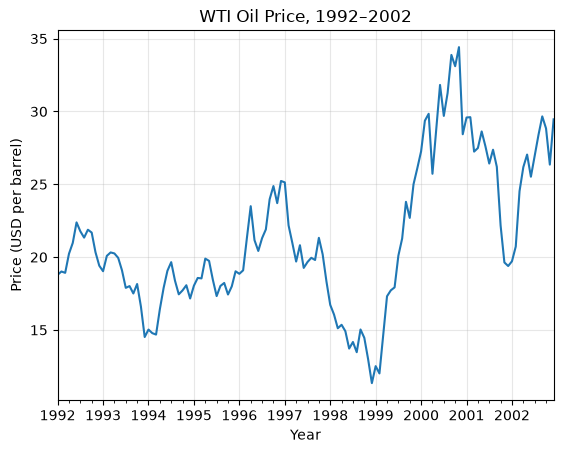

In [51]:
# Q1. Plot the average WTI price trend of oil from 1992-2002.

wti_avg = wti_df.loc['1992':'2002', 'Price'].resample('ME').mean()
wti_avg.plot()

plt.title('WTI Oil Price, 1992–2002')
plt.ylabel('Price (USD per barrel)')
plt.xlabel('Year')
plt.grid(alpha=0.3)

plt.show()

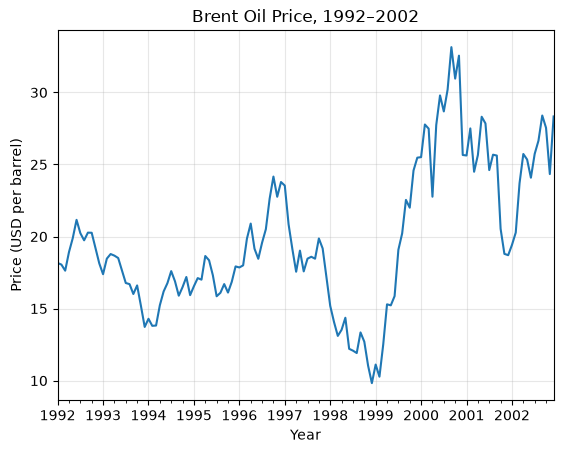

In [52]:
# Q2. Plot the average Brent price trend of oil from 1992 -2002.

brent_avg = brent_df.loc['1992':'2002', 'Price'].resample('ME').mean()
brent_avg.plot()

plt.title('Brent Oil Price, 1992–2002')
plt.ylabel('Price (USD per barrel)')
plt.xlabel('Year')
plt.grid(alpha=0.3)

plt.show()

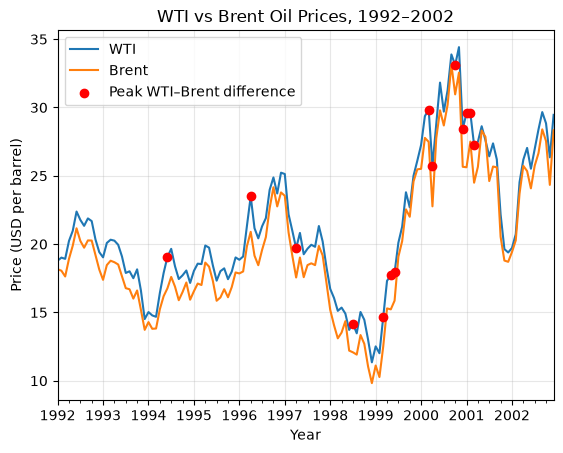

Average WTI price:   21.22 USD
Average Brent price: 19.78 USD


In [53]:
#  Q3. Compare the both the average prices of a barrel of oil from 1992-2002, indicate significant differences though markers.

spread = (wti_avg - brent_avg).abs()
big_gap = spread[spread > spread.quantile(0.9)].index

fig, ax = plt.subplots()

wti_avg.plot(ax=ax, label='WTI')
brent_avg.plot(ax=ax, label='Brent')
ax.scatter(big_gap, wti_avg[big_gap], color='red', zorder=3, label='Peak WTI–Brent difference')

ax.set_title('WTI vs Brent Oil Prices, 1992–2002')
ax.set_ylabel('Price (USD per barrel)')
ax.set_xlabel('Year')
ax.legend()
ax.grid(alpha=0.3)

plt.show()

print(f'Average WTI price:   {wti_avg.mean():.2f} USD')
print(f'Average Brent price: {brent_avg.mean():.2f} USD')

## Sales Analysis

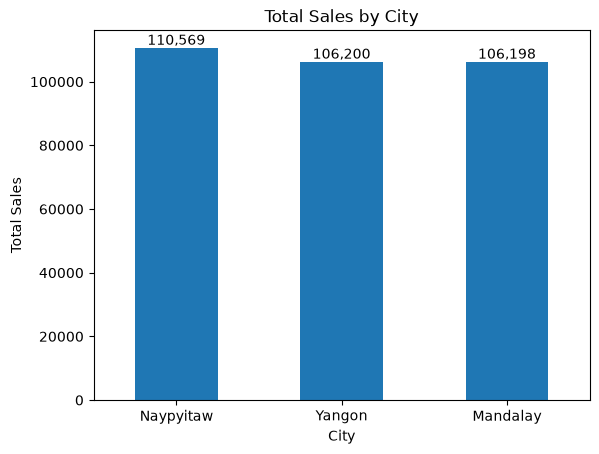

City
Naypyitaw    110568.7065
Yangon       106200.3705
Mandalay     106197.6720
Name: Total, dtype: float64

Naypyitaw contributed the most to sales: 110,568.71


In [54]:
# Q4. Plot the city wise distribution of sales, which city has contributed maximum in the sales.

city_sales = sales_df.groupby('City')['Total'].sum().sort_values(ascending=False)

ax = city_sales.plot.bar(rot=0, title='Total Sales by City', ylabel='Total Sales')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')

plt.show()

print(city_sales)
print(f'\n{city_sales.idxmax()} contributed the most to sales: {city_sales.max():,.2f}')

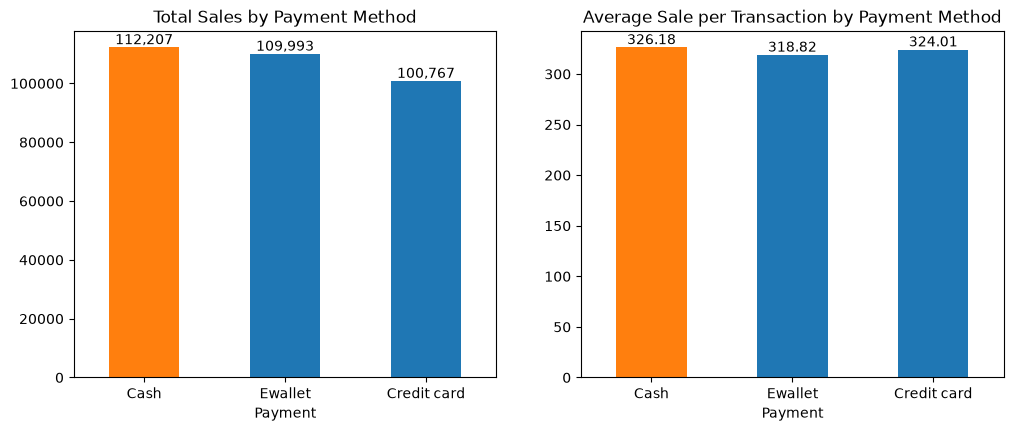

                    sum  count        mean
Payment                                   
Cash         112206.570    344  326.181890
Ewallet      109993.107    345  318.820600
Credit card  100767.072    311  324.009878

Cash contributes the most to sales: 112,206.57


In [55]:
# Q5. Does payment methods have impact on sales, which payment method is contributing to the sales.

payment_stats = sales_df.groupby('Payment')['Total'].agg(['sum', 'count', 'mean']).sort_values('sum', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, title, fmt in zip(axes, ['sum', 'mean'], ['Total Sales', 'Average Sale per Transaction'],
                               ['{:,.0f}', '{:,.2f}']):
    payment_stats[col].plot.bar(ax=ax, color=['tab:orange', 'tab:blue', 'tab:blue'], rot=0,
                                title=f'{title} by Payment Method')
    ax.bar_label(ax.containers[0], fmt=fmt)
    
plt.show()

print(payment_stats)
print(f"\n{payment_stats['sum'].idxmax()} contributes the most to sales: {payment_stats['sum'].max():,.2f}")

## Image Analysis

(487, 626) uint8


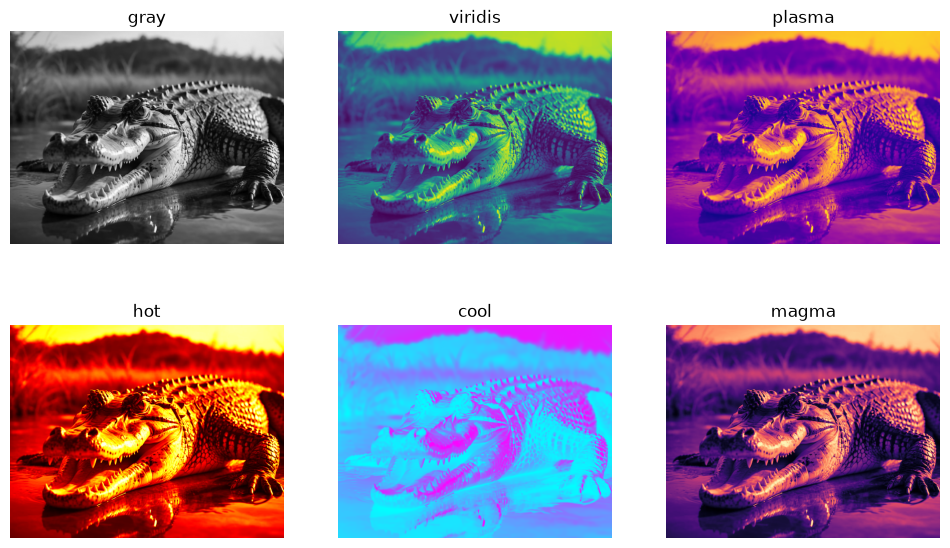

In [65]:
# Q6. Read the image ‘2.jpg’ into a NumPy array, apply six different types of ‘cmaps’, and put these images six subplots.

img_arr = np.array(img.convert('L'))
print(img_arr.shape, img_arr.dtype)

cmaps = ['gray', 'viridis', 'plasma', 'hot', 'cool', 'magma']

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, cmap in zip(axes.flat, cmaps):
    ax.imshow(img_arr, cmap=cmap)
    ax.set_title(cmap)
    ax.axis('off')
    
plt.show()

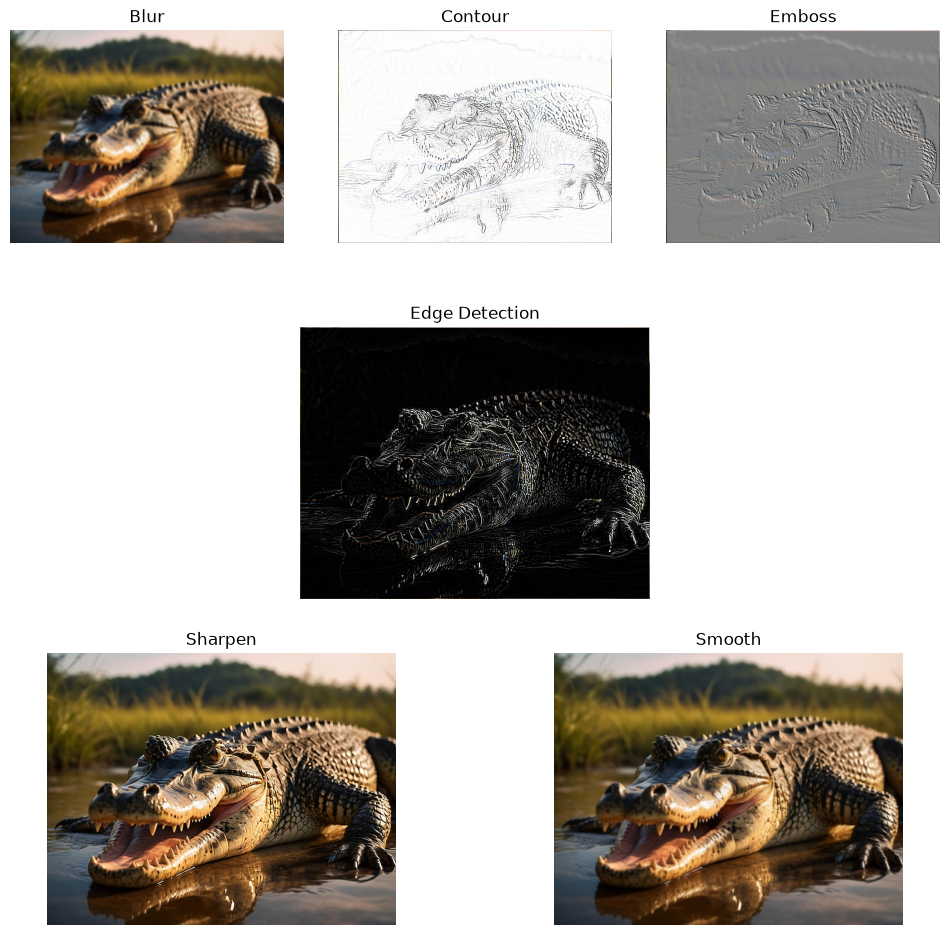

In [63]:
# Q7. Apply six basic filters on image ‘2.jpg’.

from PIL import ImageFilter

filters = {
    'Blur': ImageFilter.BLUR,
    'Contour': ImageFilter.CONTOUR,
    'Emboss': ImageFilter.EMBOSS,
    'Edge Detection': ImageFilter.FIND_EDGES,
    'Sharpen': ImageFilter.SHARPEN,
    'Smooth': ImageFilter.SMOOTH,
}

positions = [(3, 3, 1), (3, 3, 2), (3, 3, 3), (3, 1, 2), (3, 2, 5), (3, 2, 6)]

plt.figure(figsize=(12, 12))
for (name, f), pos in zip(filters.items(), positions):
    plt.subplot(*pos)
    plt.imshow(img.filter(f))
    plt.title(name)
    plt.axis('off')

plt.show()